In [22]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

# Ruta del dataset balanceado
BALANCED_DIR = os.path.join(".", "balancing", "dataset_balanced")

In [23]:
# Contar el número de imágenes por cada subcarpeta de clase
data = []
if os.path.exists(BALANCED_DIR):
    for cls in os.listdir(BALANCED_DIR):
        cls_path = os.path.join(BALANCED_DIR, cls)
        if os.path.isdir(cls_path):
            count = len(
                [
                    f
                    for f in os.listdir(cls_path)
                    if f.lower().endswith((".jpg", ".png", ".jpeg"))
                ]
            )
            data.append({"Classe": cls, "No de imagens": count})

df_balanced = (
    pd.DataFrame(data).sort_values(by="Classe").reset_index(drop=True)
)

print("--- RESUMEN DE CLASES POST-BALANCEO ---")
print(df_balanced.to_string(index=False))
print(f"\nTotal de imágenes en entrenamiento: {df_balanced['No de imagens'].sum()}")

--- RESUMEN DE CLASES POST-BALANCEO ---
Classe  No de imagens
 akiec           1000
   bcc           1000
   bkl           1000
    df           1000
   mel           1000
    nv           1000
  vasc           1000

Total de imágenes en entrenamiento: 7000


/tmp/ipykernel_47101/763862586.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


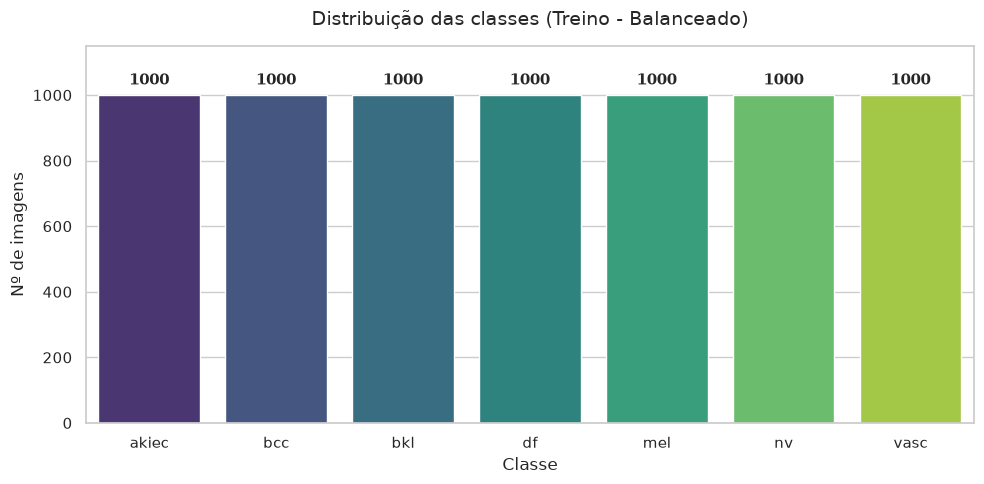

In [24]:
# Graficar la distribución idéntica al formato original
fig, ax = plt.subplots(figsize=(10, 5))

palette = sns.color_palette("viridis", len(df_balanced))
bars = sns.barplot(
    data=df_balanced, x="Classe", y="No de imagens", palette=palette, ax=ax
)

# Agregar etiquetas numéricas sobre las barras
for p in bars.patches:
    height = int(p.get_height())
    ax.annotate(
        f"{height}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title(
    "Distribuição das classes (Treino - Balanceado)",
    fontsize=14,
    pad=15,
)
ax.set_xlabel("Classe", fontsize=12)
ax.set_ylabel("Nº de imagens", fontsize=12)
ax.set_ylim(0, max(df_balanced["No de imagens"]) * 1.15)

plt.tight_layout()
plt.show()

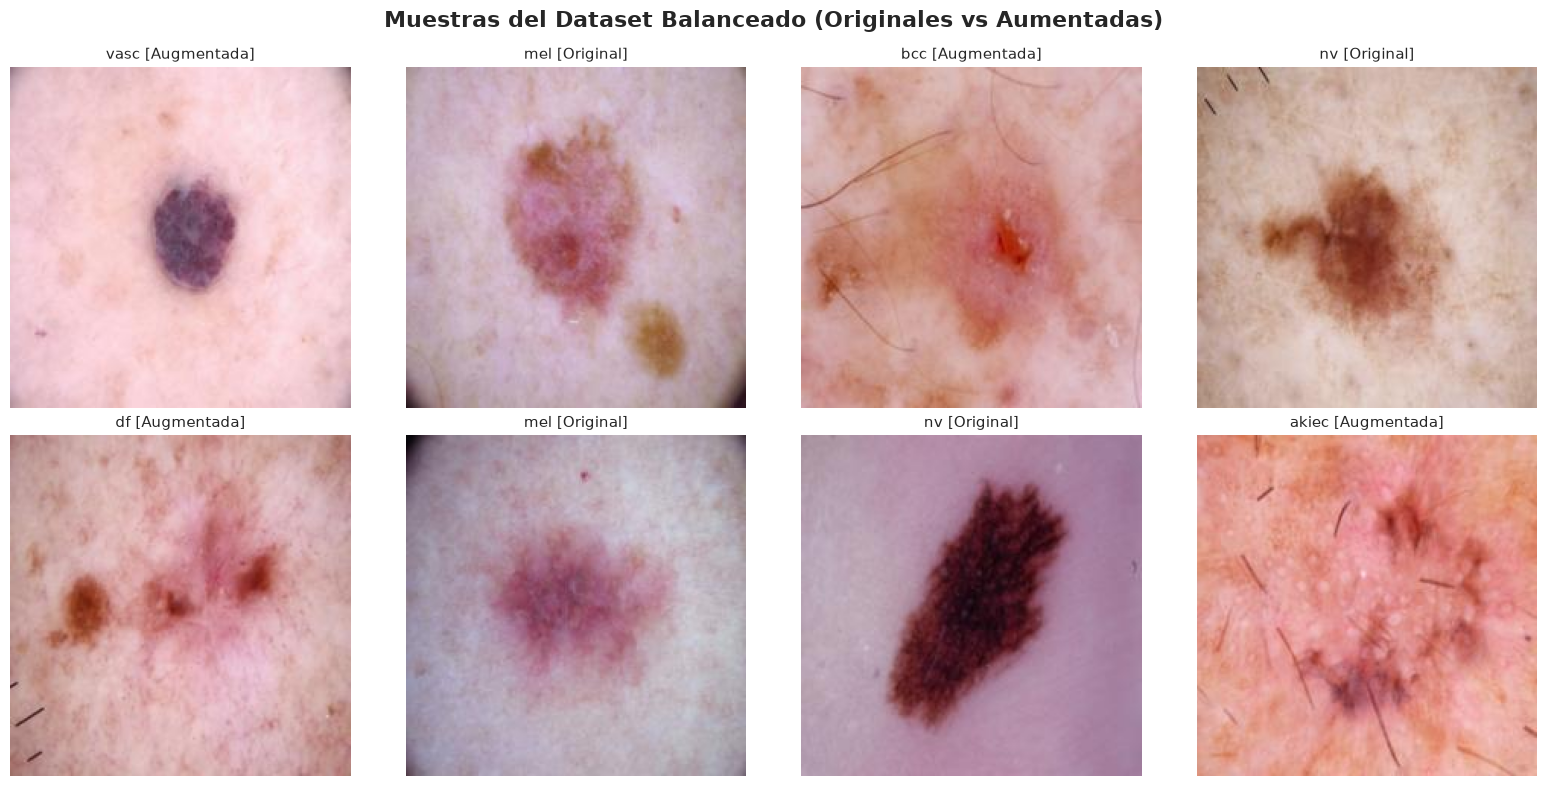

In [27]:
import random
from PIL import Image

# Mostrar una muestra de imágenes originales y aumentadas
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle(
    "Muestras del Dataset Balanceado (Originales vs Aumentadas)",
    fontsize=16,
    fontweight="bold",
)

all_images = []
for cls in df_balanced["Classe"]:
    cls_path = os.path.join(BALANCED_DIR, cls)
    imgs = [
        os.path.join(cls_path, f)
        for f in os.listdir(cls_path)
        if f.lower().endswith((".jpg", ".png"))
    ]
    all_images.extend(imgs)

sampled_imgs = random.sample(all_images, 8)

for i, img_path in enumerate(sampled_imgs):
    row, col = i // 4, i % 4
    img = Image.open(img_path)
    cls_name = os.path.basename(os.path.dirname(img_path))
    file_name = os.path.basename(img_path)

    is_aug = "_aug_" in file_name
    tag = "[Augmentada]" if is_aug else "[Original]"

    axes[row, col].imshow(img)
    axes[row, col].set_title(f"{cls_name} {tag}", fontsize=11)
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()